# Phase 1 — AI Phishing & Malicious URL Detector for Banks
CET433 – Selected Topics in Cyber · Fall 2026 · Elsewedy University of Technology

## 1. Setup

In [1]:
import os, sys, io, zipfile, urllib.request, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
REPO_URL = "https://github.com/omar-gaafer/Geek.ai.git"

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = Path("/content/project")
    if REPO_URL and not ROOT.exists():
        os.system(f"git clone -q {REPO_URL} {ROOT}")
    (ROOT / "src").mkdir(parents=True, exist_ok=True)
    if not (ROOT / "src" / "feature_extractor.py").exists():
        from google.colab import files
        print("Upload feature_extractor.py ...")
        up = files.upload()
        for name, data in up.items():
            (ROOT / "src" / name).write_bytes(data)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_RAW = ROOT / "data" / "raw"
FIG_DIR  = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for d in (DATA_RAW, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
print("Colab:", IN_COLAB, "| project root:", ROOT)

Colab: False | project root: C:\Users\Omar Gaafer\OneDrive - El Sewedy University of Technology\Desktop\Semester 7\Selected Topic in Network and Security I\Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from feature_extractor import (
    get_host, registered_domain, extract_features, extract_full_url_features,
    HOST_NUMERIC_FEATURES, HOST_CATEGORICAL_FEATURES, FULL_URL_EXTRA_FEATURES,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

pandas 3.1.1 | scikit-learn 1.9.1


### Data download

In [3]:
DRIVE_FOLDER = "https://drive.google.com/drive/folders/1w_0md9dmjnYGvht6pmoRgVm0mA4EkI0_"
DRIVE_FILES = {   # path inside data/raw  ->  Google Drive file id
    "phiusiil/PhiUSIIL_Phishing_URL_Dataset.csv": "1Z1bl8sC20liaBjJItHhPpBKyMEFxipZo",
    "iscx/malicious_phish.csv":                   "115okhAOU-JQlPrHzymJRCnUrCl8UYmKv",
    "openphish/feed_2026-11-21.txt":              "1pl6VScQdvcaWreY57KOZ26dFB3c_iY1j",
}

def fetch_from_drive(rel_path, file_id):
    dest = DATA_RAW / rel_path
    if dest.exists() and dest.stat().st_size > 0:
        print(f"✔ already here : {rel_path}")
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    try:
        import gdown
    except ImportError:
        os.system(f"{sys.executable} -m pip install -q gdown")
        import gdown
    try:
        print(f"↓ downloading  : {rel_path}")
        gdown.download(id=file_id, output=str(dest), quiet=True)
        ok = dest.exists() and dest.stat().st_size > 0
    except Exception as e:
        print(f"  Drive failed ({type(e).__name__}: {e})")
        ok = False
    if not ok and dest.exists():
        dest.unlink()                      # don't leave a broken / empty file behind
    print(f"  {'✔ ok' if ok else '✘ not downloaded (fallback will be used)'}")
    return ok

for rel, fid in DRIVE_FILES.items():
    fetch_from_drive(rel, fid)

✔ already here : phiusiil/PhiUSIIL_Phishing_URL_Dataset.csv
✔ already here : iscx/malicious_phish.csv
✔ already here : openphish/feed_2026-11-21.txt


## 2. Load data — PhiUSIIL Phishing URL Dataset

In [4]:
PHIUSIIL_CSV = DATA_RAW / "phiusiil" / "PhiUSIIL_Phishing_URL_Dataset.csv"
PHIUSIIL_ZIP_URL = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"

if not PHIUSIIL_CSV.exists():
    print("Downloading PhiUSIIL from UCI ...")
    PHIUSIIL_CSV.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(PHIUSIIL_ZIP_URL, timeout=600) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(PHIUSIIL_CSV.parent)

raw = pd.read_csv(PHIUSIIL_CSV, usecols=["URL", "label"])
print("shape:", raw.shape)
print("\nOriginal label counts (1 = legit in PhiUSIIL):")
print(raw["label"].value_counts())

df = pd.DataFrame({
    "url":   raw["URL"].astype(str).str.strip(),
    "label": 1 - raw["label"],          # flip -> 1 = phishing, 0 = legit
})
print("\nAfter flip (1 = phishing):")
print(df["label"].value_counts())
df.sample(5, random_state=RANDOM_STATE)

shape: (235795, 2)

Original label counts (1 = legit in PhiUSIIL):
label
1    134850
0    100945
Name: count, dtype: int64

After flip (1 = phishing):
label
0    134850
1    100945
Name: count, dtype: int64


,url,label
136221,https://www.northcm.ac.th,0
56609,https://unitedmartialartscenters.com/at0/mygov/personal.html,1
46393,https://email.mail1.onesignal.os.tc/c/ejwcz02untamqohvwmwoczwfbgw6uduohnspqdycugml7r66...,1
129746,http://uqr.to/1il1z,1
131464,https://www.woolworthsrewards.com.au,0


## 3. Cleaning

In [5]:
n0 = len(df)
df = df.dropna().query("url != ''").drop_duplicates("url")
print(f"duplicate / empty URLs removed : {n0 - len(df):,}")

df["host"] = df["url"].map(get_host)
df = df[df["host"] != ""]

conflict = df.groupby("host")["label"].nunique()
conflict_hosts = set(conflict[conflict > 1].index)
print(f"hosts with conflicting labels  : {len(conflict_hosts):,} (dropped)")
df = df[~df["host"].isin(conflict_hosts)]

n1 = len(df)
df = df.drop_duplicates("host").reset_index(drop=True)
print(f"duplicate hosts removed        : {n1 - len(df):,}")
print(f"final rows                     : {len(df):,}")
print(df["label"].value_counts(normalize=True).rename({0: "legit", 1: "phishing"}).round(3))

duplicate / empty URLs removed : 425


hosts with conflicting labels  : 58 (dropped)
duplicate hosts removed        : 16,175
final rows                     : 219,036
label
legit       0.615
phishing    0.385
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis
### 4.1 Class distribution

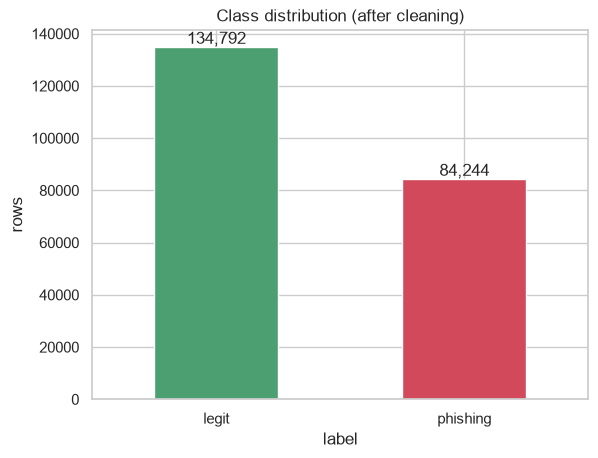

In [6]:
ax = df["label"].map({0: "legit", 1: "phishing"}).value_counts().plot.bar(color=["#4C9F70", "#D1495B"], rot=0)
ax.set_title("Class distribution (after cleaning)"); ax.set_ylabel("rows")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
savefig("01_class_distribution"); plt.show()

### 4.2 Collection shortcuts

label                          legit  phishing
starts with https              100.0      44.7
host starts with www.          100.0      46.9
has a path after domain          0.0      18.3
has a subdomain (besides www)    4.0      55.3


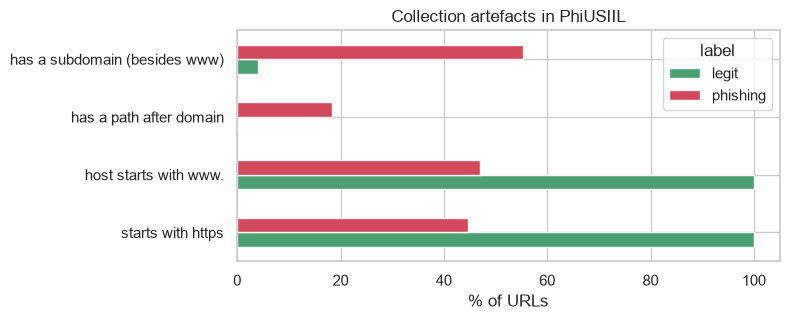

In [7]:
u = df["url"]
shortcut = pd.DataFrame({
    "starts with https":      u.str.lower().str.startswith("https://"),
    "host starts with www.":  u.str.replace(r"^[a-zA-Z]+://", "", regex=True).str.lower().str.startswith("www."),
    "has a path after domain": u.str.contains(r"^[a-zA-Z]+://[^/]+/.", regex=True),
    "has a subdomain (besides www)": df["host"] != df["host"].map(registered_domain),
    "label": df["label"].map({0: "legit", 1: "phishing"}),
}).groupby("label").mean().T.mul(100).round(1)
display(shortcut) if "display" in dir() else print(shortcut)

shortcut.plot.barh(color=["#4C9F70", "#D1495B"], figsize=(7, 3))
plt.xlabel("% of URLs"); plt.title("Collection artefacts in PhiUSIIL")
savefig("02_shortcuts"); plt.show()

### 4.3 Hostname characteristics

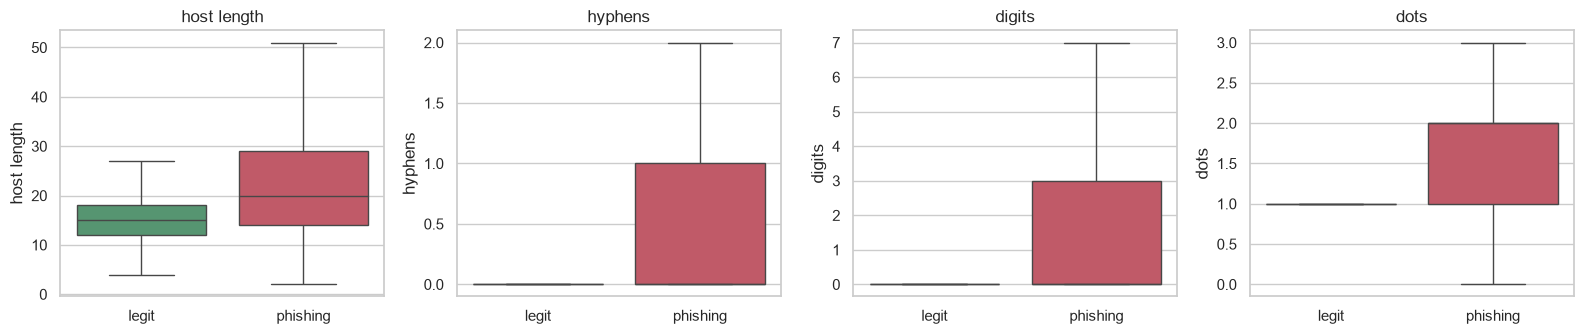

TLDs with the highest phishing rate (>= 300 rows):


,rows,phishing rate
tld,,
cf,1176,1.000
gq,476,1.000
page,311,1.000
top,1962,0.999
ml,963,0.999
ga,1098,0.996
site,1274,0.996
link,1175,0.993
fun,375,0.989


In [8]:
h = df["host"]
eda = pd.DataFrame({
    "host length": h.str.len(),
    "hyphens":     h.str.count("-"),
    "digits":      h.str.count(r"\d"),
    "dots":        h.str.count(r"\."),
    "label":       df["label"].map({0: "legit", 1: "phishing"}),
})
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["host length", "hyphens", "digits", "dots"]):
    sns.boxplot(data=eda, x="label", y=col, ax=ax, showfliers=False, palette=["#4C9F70", "#D1495B"])
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); savefig("03_host_boxplots"); plt.show()

tld = df.assign(tld=h.str.rsplit(".", n=1).str[-1])
top_tld = (tld.groupby("tld")["label"].agg(["count", "mean"])
              .query("count >= 300").sort_values("mean", ascending=False))
top_tld.columns = ["rows", "phishing rate"]
print("TLDs with the highest phishing rate (>= 300 rows):")
top_tld.head(12).round(3)

## 5. Feature extraction

In [9]:
X = pd.DataFrame([extract_features(x) for x in df["host"]])
y = df["label"].to_numpy()
print("X shape:", X.shape)
X.head()

X shape: (219036, 13)


,host_length,num_labels,num_hyphens,num_digits,digit_ratio,vowel_ratio,entropy,longest_label,is_ip,has_punycode,num_sensitive_words,is_free_hosting,tld
0,20,2,0,0,0.0,0.368421,3.546439,16,0,0,1,0,com
1,12,2,1,0,0.0,0.500000,3.251629,9,0,0,0,0,de
2,18,3,0,0,0.0,0.500000,3.572431,12,0,0,0,0,uk
3,15,2,0,0,0.0,0.285714,3.506891,11,0,0,0,0,com
4,22,2,0,0,0.0,0.380952,3.413088,18,0,0,0,0,org


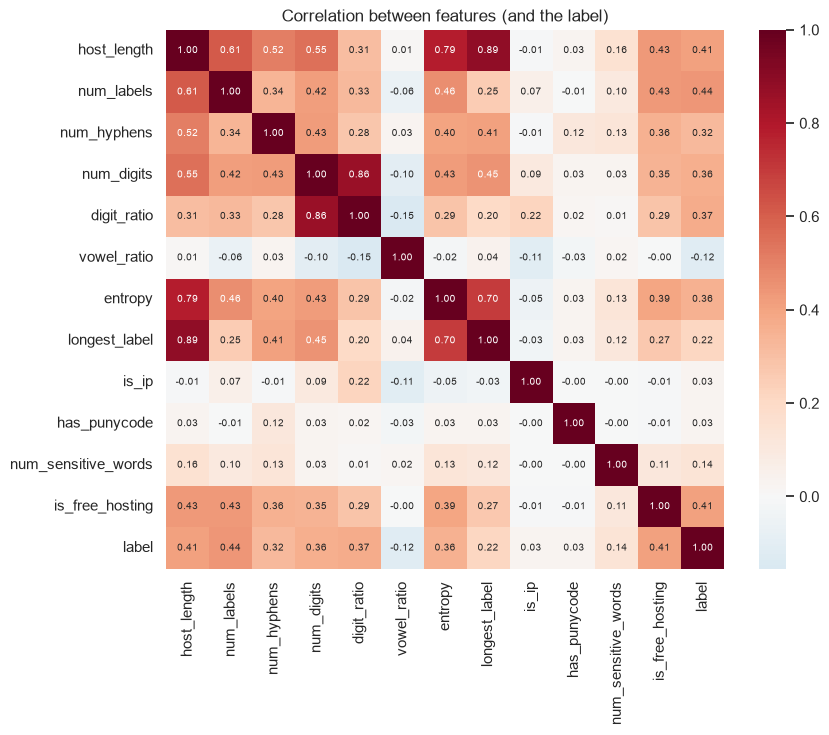

In [10]:
plt.figure(figsize=(9, 7))
corr = X[HOST_NUMERIC_FEATURES].assign(label=y).corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation between features (and the label)")
savefig("04_correlation_heatmap"); plt.show()

## 6. Train / validation / test split

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

reg = df["host"].map(registered_domain)

# Shared platforms (web.app, firebaseapp.com, repl.co ...) host thousands of DIFFERENT people's sites.
# Treating "web.app" as one group would drop ~5,500 easy phishing rows into a single split and make
# that split's score depend on luck. So: a registered domain with > 100 hosts = shared platform
# -> each host is its own group. Everything else is grouped by registered domain.
reg_size = reg.map(reg.value_counts())
groups = np.where(reg_size > 100, df["host"], reg)
print("shared platforms split per host:", reg[reg_size > 100].nunique(),
      "| largest remaining group:", pd.Series(groups).value_counts().iloc[0], "rows")

# 20 folds that keep each domain in ONE fold and keep the phishing rate similar in every fold.
# 14 folds -> train (70%), 3 -> validation (15%), 3 -> test (15%)
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=RANDOM_STATE)
fold = np.empty(len(y), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(X, y, groups)):
    fold[idx] = k
test_idx  = np.where(fold < 3)[0]
val_idx   = np.where((fold >= 3) & (fold < 6))[0]
train_idx = np.where(fold >= 6)[0]

X_train, y_train = X.iloc[train_idx], y[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y[test_idx]

summary = pd.DataFrame({
    "rows": [len(train_idx), len(val_idx), len(test_idx)],
    "share": np.round([len(train_idx)/len(X), len(val_idx)/len(X), len(test_idx)/len(X)], 3),
    "phishing rate": np.round([y_train.mean(), y_val.mean(), y_test.mean()], 3),
}, index=["train", "validation", "test"])
summary

shared platforms split per host: 50 | largest remaining group: 100 rows


,rows,share,phishing rate
train,153330,0.70,0.385
validation,32853,0.15,0.385
test,32853,0.15,0.385


### Leakage check 1: no shared domains

In [12]:
g_train, g_val, g_test = set(groups[train_idx]), set(groups[val_idx]), set(groups[test_idx])
print("domains shared train ∩ val :", len(g_train & g_val))
print("domains shared train ∩ test:", len(g_train & g_test))
print("domains shared val   ∩ test:", len(g_val & g_test))
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test)
print("✅ no domain appears in more than one split")

domains shared train ∩ val : 0
domains shared train ∩ test: 0
domains shared val   ∩ test: 0
✅ no domain appears in more than one split


## 7. Baseline model — Logistic Regression pipeline

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

def make_preprocessor(numeric_cols, categorical_cols):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), categorical_cols),
    ])

baseline = Pipeline([
    ("prep", make_preprocessor(HOST_NUMERIC_FEATURES, HOST_CATEGORICAL_FEATURES)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])
baseline.fit(X_train, y_train)      # <-- fit on TRAIN only
baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['host_length','num_labels','num_hyphens',...,'num_sensitive_words', 'is_free_hosting','tld']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

### Leakage check 2: scaler fitted on train only

In [14]:
scaler = baseline.named_steps["prep"].named_transformers_["num"].named_steps["scale"]
check = pd.DataFrame({
    "scaler.mean_": scaler.mean_,
    "train mean":   X_train[HOST_NUMERIC_FEATURES].mean().to_numpy(),
    "full-data mean": X[HOST_NUMERIC_FEATURES].mean().to_numpy(),
}, index=HOST_NUMERIC_FEATURES).round(4)
assert np.allclose(check["scaler.mean_"], check["train mean"])
print("✅ scaler statistics == training-set statistics")
check.head(6)

✅ scaler statistics == training-set statistics


,scaler.mean_,train mean,full-data mean
host_length,18.2814,18.2814,18.2977
num_labels,2.3870,2.3870,2.3889
num_hyphens,0.2652,0.2652,0.2692
num_digits,0.8159,0.8159,0.8207
digit_ratio,0.0304,0.0304,0.0304
vowel_ratio,0.3606,0.3606,0.3604


## 8. Evaluation
### 8.1 Dummy baseline

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p = dummy.predict(X_test)
print(f"Dummy (always 'legit')  accuracy = {accuracy_score(y_test, p):.3f}   "
      f"recall = {recall_score(y_test, p, zero_division=0):.3f}   F1 = {f1_score(y_test, p, zero_division=0):.3f}")
print(f"→ {accuracy_score(y_test, p):.0%} accuracy while catching zero phishing URLs.")

Dummy (always 'legit')  accuracy = 0.615   recall = 0.000   F1 = 0.000
→ 62% accuracy while catching zero phishing URLs.


### 8.2 Logistic Regression: train vs validation vs test

In [16]:
def scores(model, X_, y_, threshold=0.5):
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy":  accuracy_score(y_, pred),
        "precision": precision_score(y_, pred),
        "recall":    recall_score(y_, pred),
        "F1":        f1_score(y_, pred),
        "ROC-AUC":   roc_auc_score(y_, proba),
        "PR-AUC":    average_precision_score(y_, proba),
    }

results = pd.DataFrame({
    "train": scores(baseline, X_train, y_train),
    "validation": scores(baseline, X_val, y_val),
    "test": scores(baseline, X_test, y_test),
}).T.round(4)
results

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
train,0.8519,0.8800,0.7120,0.7871,0.8880,0.8864
validation,0.8487,0.8723,0.7106,0.7832,0.8849,0.8836
test,0.8471,0.8749,0.7031,0.7797,0.8843,0.8820


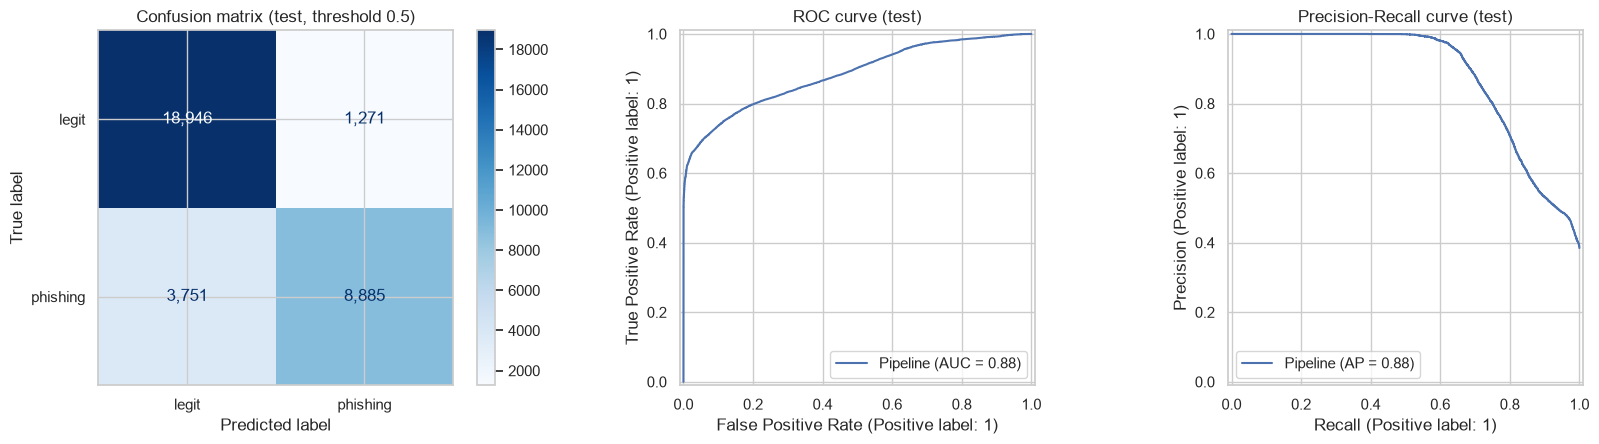

TP=8,885  FP=1,271  TN=18,946  FN=3,751
False-positive rate = 6.29%  (legit sites blocked)
Miss rate (FN rate) = 29.69%  (phishing that got through)



              precision    recall  f1-score   support

       legit      0.835     0.937     0.883     20217
    phishing      0.875     0.703     0.780     12636

    accuracy                          0.847     32853
   macro avg      0.855     0.820     0.831     32853
weighted avg      0.850     0.847     0.843     32853



In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ConfusionMatrixDisplay.from_estimator(baseline, X_test, y_test, display_labels=["legit", "phishing"],
                                      cmap="Blues", values_format=",", ax=axes[0])
axes[0].set_title("Confusion matrix (test, threshold 0.5)")
RocCurveDisplay.from_estimator(baseline, X_test, y_test, ax=axes[1]); axes[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_estimator(baseline, X_test, y_test, ax=axes[2]); axes[2].set_title("Precision-Recall curve (test)")
plt.tight_layout(); savefig("05_baseline_evaluation"); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, baseline.predict(X_test)).ravel()
print(f"TP={tp:,}  FP={fp:,}  TN={tn:,}  FN={fn:,}")
print(f"False-positive rate = {fp/(fp+tn):.2%}  (legit sites blocked)")
print(f"Miss rate (FN rate) = {fn/(fn+tp):.2%}  (phishing that got through)")
print()
print(classification_report(y_test, baseline.predict(X_test), target_names=["legit", "phishing"], digits=3))

### 8.3 Coefficients

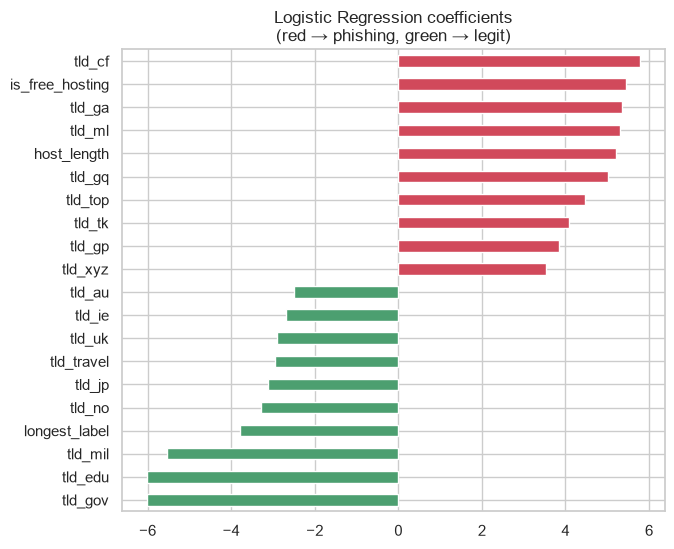

In [18]:
names = baseline.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=names)
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()
top.plot.barh(figsize=(7, 6), color=np.where(top > 0, "#D1495B", "#4C9F70"))
plt.title("Logistic Regression coefficients\n(red → phishing, green → legit)")
savefig("06_lr_coefficients"); plt.show()

## 9. Shortcut experiment: full URL vs host-only

In [19]:
X_full = pd.DataFrame([extract_full_url_features(u_) for u_ in df["url"]])
FULL_NUMERIC = HOST_NUMERIC_FEATURES + FULL_URL_EXTRA_FEATURES

shortcut_model = Pipeline([
    ("prep", make_preprocessor(FULL_NUMERIC, HOST_CATEGORICAL_FEATURES)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])
shortcut_model.fit(X_full.iloc[train_idx], y_train)

compare = pd.DataFrame({
    "host-only (our model)": scores(baseline, X_test, y_test),
    "full URL (shortcut)":   scores(shortcut_model, X_full.iloc[test_idx], y_test),
}).T.round(4)
compare

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
host-only (our model),0.8471,0.8749,0.7031,0.7797,0.8843,0.8820
full URL (shortcut),0.9990,1.0000,0.9973,0.9987,0.9991,0.9992


## 10. External sanity check

In [20]:
bank_urls = [
    "https://www.cibeg.com/en/personal",
    "https://cibeg.com/en/personal/accounts-and-deposits",
    "https://online.cibeg.com/",
    "https://www.nbe.com.eg/NBE/E/#/EN/Home",
    "https://www.banquemisr.com/en/Home/PERSONAL",
    "https://www.qnbalahli.com/sites/qnb/qnbegypt/page/en/enhome.html",
    "https://www.aaib.com/personal",
    "https://www.hsbc.com.eg/accounts/",
    "https://www.alexbank.com/En/Personal",
    "https://www.chase.com/personal/checking",
    "https://secure.chase.com/web/auth/dashboard",
    "https://www.bankofamerica.com/online-banking/",
    "https://www.paypal.com/eg/signin",
    "https://login.microsoftonline.com/",
    "http://github.com/login",
]

def predict_both(urls):
    urls = list(urls)
    p_host = baseline.predict_proba(pd.DataFrame([extract_features(x) for x in urls]))[:, 1]
    p_full = shortcut_model.predict_proba(pd.DataFrame([extract_full_url_features(x) for x in urls]))[:, 1]
    return p_host, p_full

p_host, p_full = predict_both(bank_urls)
banks = pd.DataFrame({"url": bank_urls,
                      "P(phish) host-only": p_host.round(3),
                      "P(phish) full URL":  p_full.round(3)})
print(f"Flagged as phishing (>=0.5):  host-only = {(p_host>=.5).sum()}/{len(bank_urls)}   "
      f"full URL = {(p_full>=.5).sum()}/{len(bank_urls)}")
banks

Flagged as phishing (>=0.5):  host-only = 7/15   full URL = 15/15


,url,P(phish) host-only,P(phish) full URL
0,https://www.cibeg.com/en/personal,0.271,1.000
1,https://cibeg.com/en/personal/accounts-and-deposits,0.271,1.000
2,https://online.cibeg.com/,0.776,1.000
3,https://www.nbe.com.eg/NBE/E/#/EN/Home,0.560,1.000
4,https://www.banquemisr.com/en/Home/PERSONAL,0.260,1.000
5,https://www.qnbalahli.com/sites/qnb/qnbegypt/page/en/enhome.html,0.281,1.000
6,https://www.aaib.com/personal,0.215,0.996
7,https://www.hsbc.com.eg/accounts/,0.617,1.000
8,https://www.alexbank.com/En/Personal,0.574,1.000
9,https://www.chase.com/personal/checking,0.271,1.000


In [21]:
external = []

# --- Kaggle benign (optional file) ---
kaggle_csv = DATA_RAW / "iscx" / "malicious_phish.csv"
if kaggle_csv.exists():
    kag = pd.read_csv(kaggle_csv)
    kag_benign = kag.loc[kag["type"] == "benign", "url"].sample(20_000, random_state=RANDOM_STATE)
    ph, pf = predict_both(kag_benign)
    external.append({"dataset": "Kaggle benign (20k)", "true class": "legit",
                     "flagged phishing — host-only": (ph >= .5).mean(),
                     "flagged phishing — full URL":  (pf >= .5).mean()})
else:
    print("Kaggle file not found → skipped")

# --- OpenPhish (local snapshot, or live feed in Colab) ---
op_files = sorted((DATA_RAW / "openphish").glob("feed_*.txt"))
if op_files:
    op_urls = [l.strip() for l in op_files[-1].read_text(encoding="utf-8").splitlines() if l.strip()]
    src = op_files[-1].name
else:
    try:
        req = urllib.request.Request("https://openphish.com/feed.txt", headers={"User-Agent": "Mozilla/5.0"})
        op_urls = urllib.request.urlopen(req, timeout=30).read().decode().split()
        src = "live feed"
    except Exception as e:
        op_urls, src = [], f"unavailable ({e})"
if op_urls:
    ph, pf = predict_both(op_urls)
    external.append({"dataset": f"OpenPhish {src} ({len(op_urls)})", "true class": "phishing",
                     "flagged phishing — host-only": (ph >= .5).mean(),
                     "flagged phishing — full URL":  (pf >= .5).mean()})

ext = pd.DataFrame(external).set_index("dataset") if external else pd.DataFrame()
for c in [c for c in ext.columns if c.startswith("flagged")]:
    ext[c] = (ext[c] * 100).round(1).astype(str) + "%"
ext

,true class,flagged phishing — host-only,flagged phishing — full URL
dataset,,,
Kaggle benign (20k),legit,22.0%,99.9%
OpenPhish feed_2026-11-21.txt (300),phishing,92.7%,100.0%


## 11. Business metric

In [22]:
COST_FN, COST_FP, COST_TRIAGE = 4500, 15, 35 * 5 / 60

def business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn * COST_FN + fp * COST_FP + (tp + fp) * COST_TRIAGE

pred_test = baseline.predict(X_test)
cost_model = business_cost(y_test, pred_test)
cost_nothing = business_cost(y_test, np.zeros_like(y_test))   # no detection: every phishing gets through
print(f"Test set: {len(y_test):,} URLs ({y_test.sum():,} phishing)")
print(f"Cost with NO detection : ${cost_nothing:,.0f}")
print(f"Cost with baseline LR  : ${cost_model:,.0f}")
print(f"Loss avoided           : ${cost_nothing - cost_model:,.0f}  ({1 - cost_model/cost_nothing:.1%})")

Test set: 32,853 URLs (12,636 phishing)
Cost with NO detection : $56,862,000
Cost with baseline LR  : $16,928,187
Loss avoided           : $39,933,813  (70.2%)


## 12. Save model

In [23]:
import joblib
joblib.dump(baseline, MODEL_DIR / "baseline_logreg.joblib")
print("saved →", MODEL_DIR / "baseline_logreg.joblib")

# quick reload test, exactly how the demo will use it
m = joblib.load(MODEL_DIR / "baseline_logreg.joblib")
for test_url in ["https://www.cibeg.com/en/personal", "http://cib-egypt-secure-login.xyz/verify"]:
    p_ = m.predict_proba(pd.DataFrame([extract_features(test_url)]))[0, 1]
    print(f"{p_:.3f}  {test_url}")

saved → C:\Users\Omar Gaafer\OneDrive - El Sewedy University of Technology\Desktop\Semester 7\Selected Topic in Network and Security I\Project\models\baseline_logreg.joblib
0.271  https://www.cibeg.com/en/personal
1.000  http://cib-egypt-secure-login.xyz/verify


In [24]:
print("=" * 60)
print("PHASE 1 SUMMARY")
print("=" * 60)
print(f"Data     : PhiUSIIL, {len(df):,} unique hosts ({y.mean():.1%} phishing)")
print(f"Split    : group split by domain 70/15/15 — train {len(train_idx):,} / val {len(val_idx):,} / test {len(test_idx):,}")
print(f"Features : {len(HOST_NUMERIC_FEATURES)} numeric + TLD (host-only)")
r = results.loc["test"]
print(f"Baseline : Logistic Regression — test precision {r['precision']:.3f}, recall {r['recall']:.3f}, "
      f"F1 {r['F1']:.3f}, ROC-AUC {r['ROC-AUC']:.3f}")
print(f"Shortcut : full-URL model test F1 {compare.loc['full URL (shortcut)', 'F1']:.3f} "
      f"but flags {(p_full>=.5).sum()}/{len(bank_urls)} real bank URLs (host-only: {(p_host>=.5).sum()})")
print(f"Business : loss avoided on test set ≈ ${cost_nothing - cost_model:,.0f}")

PHASE 1 SUMMARY
Data     : PhiUSIIL, 219,036 unique hosts (38.5% phishing)
Split    : group split by domain 70/15/15 — train 153,330 / val 32,853 / test 32,853
Features : 12 numeric + TLD (host-only)
Baseline : Logistic Regression — test precision 0.875, recall 0.703, F1 0.780, ROC-AUC 0.884
Shortcut : full-URL model test F1 0.999 but flags 15/15 real bank URLs (host-only: 7)
Business : loss avoided on test set ≈ $39,933,813
